[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/12_trees_forests.ipynb)

# 12 · Decision Trees & Random Forests: Twenty Questions, Then a Crowd

**Part 1 — Classical supervised learning** · Notebook 12 of 27

A decision tree predicts the way a person might reason through a problem: a sequence of yes/no questions. *Is the house bigger than 2,000 ft²? Is it downtown? Was it built after 2010?* Each answer narrows things down until you reach a prediction. Trees are interpretable, handle nonlinearity and feature interactions automatically, need almost no preprocessing (no scaling!), and work for both regression and classification. Their weakness is that a single tree is **unstable**: change the data a little and the tree can change a lot. The fix is one of the best ideas in machine learning: grow **many** different trees and let them vote. That's a **random forest**, and for tabular data it remains one of the strongest, most reliable methods there is.

**What you'll learn**

1. Trees as nested if-then rules
2. Growing a regression tree: the greedy split search, by hand and in code
3. Watching a tree grow: piecewise-constant fits and rectangular regions
4. Classification trees: Gini, entropy, and why not just count errors
5. A CART implementation from scratch
6. Overfitting, depth, and **cost-complexity pruning**
7. Why a single tree is unstable (high variance)
8. **The bootstrap**: learning about an estimate by resampling
9. **Bagging** and **random forests**: averaging away the variance, and why decorrelating the trees matters
10. **Out-of-bag error**: free cross-validation
11. **Feature importance**: impurity-based vs. permutation, and a trap

*Course map: ISYE 4600 W13 (Decision Trees & Random Forests: CART, regression and classification trees, pruning, bootstrap, bagging, random forests, OOB error, feature importance) and HW4 Q5 (CART vs. random forest on spam data); W12 (bagging vs. boosting).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.inspection import permutation_importance
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Trees as nested if-then rules

ISYE 4600 (W13) opens with house prices. A human expert might reason: *"Houses over 2,000 ft² sell for more. Among those, downtown ones are pricier. Among smaller houses, newer ones cost more."* As a tree:

```
                     Size > 2000 ft²?
                    /                \
                 yes                  no
        Location = Downtown?      Year built > 2010?
          /          \              /          \
       $500k        $400k        $350k        $240k
```

- Each **internal node** asks a yes/no question about **one** feature.
- Each **leaf** holds a prediction: an average (regression) or a majority class (classification).
- A prediction follows one path from the root to a leaf.

Geometrically, each question cuts the feature space with an **axis-aligned** line, so a tree partitions the space into **rectangles** (boxes, in more dimensions) and predicts a constant in each one.

---
## 2. Growing a regression tree: the greedy split search

How do we pick the questions? Finding the best possible tree is computationally hopeless (NP-hard), so **CART** (Classification And Regression Trees; Breiman et al., 1984) grows the tree **greedily**, top-down: at each node, try every feature $j$ and every cut point $s$, split the node's data into

$$R_1(j, s) = \{x : x_j \le s\}, \qquad R_2(j, s) = \{x : x_j > s\}$$

predict each side's **mean** ($\hat c_1, \hat c_2$), and keep the split with the smallest total squared error (ISYE W13):

$$\min_{j,\,s}\;\Big[\sum_{x^i\in R_1}(y^i - \hat c_1)^2 + \sum_{x^i\in R_2}(y^i - \hat c_2)^2\Big]$$

Then recurse into each half. Candidate cut points are just the midpoints between consecutive sorted values, so the search is finite.

### By hand: six apartments

Let's do one split search completely, in the style of ISYE's exam-score example:

In [2]:
apts = pd.DataFrame({"apartment": list("ABCDEF"), "area (100 ft²)": [3, 5, 6, 9, 11, 12],
                     "walk to campus (min)": [5, 25, 10, 20, 8, 30], "rent ($100s)": [9, 8, 12, 14, 19, 15]})
display(apts)
Xh = apts[["area (100 ft²)", "walk to campus (min)"]].values.astype(float); yh = apts["rent ($100s)"].values.astype(float)

rows = []
for j, fname in enumerate(["area (100 ft²)", "walk to campus (min)"]):
    vals = np.unique(Xh[:, j])
    for s in (vals[:-1] + vals[1:]) / 2:                       # midpoints between sorted values
        L, R = yh[Xh[:, j] <= s], yh[Xh[:, j] > s]
        sse = ((L - L.mean()) ** 2).sum() + ((R - R.mean()) ** 2).sum()
        rows.append(dict(feature=fname, cut=s, left=f"{len(L)} pts, mean {L.mean():.2f}", right=f"{len(R)} pts, mean {R.mean():.2f}", SSE=round(sse, 2)))
splits = pd.DataFrame(rows)
splits["best"] = np.where(splits.SSE == splits.SSE.min(), "✅", "")
print(f"Before splitting: predict the overall mean {yh.mean():.2f}, SSE = {((yh - yh.mean())**2).sum():.2f}")
splits

,apartment,area (100 ft²),walk to campus (min),rent ($100s)
0,A,3,5,9
1,B,5,25,8
2,C,6,10,12
3,D,9,20,14
4,E,11,8,19
5,F,12,30,15


Before splitting: predict the overall mean 12.83, SSE = 82.83


,feature,cut,left,right,SSE,best
0,area (100 ft²),4.0,"1 pts, mean 9.00","5 pts, mean 13.60",65.20,
1,area (100 ft²),5.5,"2 pts, mean 8.50","4 pts, mean 15.00",26.50,
2,area (100 ft²),7.5,"3 pts, mean 9.67","3 pts, mean 16.00",22.67,✅
3,area (100 ft²),10.0,"4 pts, mean 10.75","2 pts, mean 17.00",30.75,
4,area (100 ft²),11.5,"5 pts, mean 12.40","1 pts, mean 15.00",77.20,
5,walk to campus (min),6.5,"1 pts, mean 9.00","5 pts, mean 13.60",65.20,
6,walk to campus (min),9.0,"2 pts, mean 14.00","4 pts, mean 12.25",78.75,
7,walk to campus (min),15.0,"3 pts, mean 13.33","3 pts, mean 12.33",81.33,
8,walk to campus (min),22.5,"4 pts, mean 13.50","2 pts, mean 11.50",77.50,
9,walk to campus (min),27.5,"5 pts, mean 12.40","1 pts, mean 15.00",77.20,


The best first question is "area ≤ 7.5?", which splits the apartments into small (mean rent \$967) and large (mean \$1,600) and cuts the squared error by more than half. The algorithm would then repeat the same search inside each half.

> 🤔 **Question: Why not choose the split that's best two levels down, instead of greedily?**
>
> Because looking ahead multiplies the cost: with $d$ features and $n$ cut points per feature there are $dn$ choices per node, so a two-level lookahead is $(dn)^3$, and so on. Greedy is fast and usually good enough. Its known blind spot: interactions that only show up after two splits (like XOR, where neither feature alone helps). Ensembles (section 9) soften that weakness.

---
## 3. Watching a tree grow

With one input feature, a regression tree's prediction is a **step function**: each leaf is a flat segment. Deeper trees have more, finer steps. 🎚️ **Change the depth.**

In [3]:
r_ = np.random.default_rng(0)
x1 = np.sort(r_.uniform(0, 10, 120)); y1 = np.sin(x1) + 0.3 * x1 + r_.normal(0, 0.35, 120)
x1_test = np.sort(r_.uniform(0, 10, 2000)); y1_test = np.sin(x1_test) + 0.3 * x1_test + r_.normal(0, 0.35, 2000)
xx = np.linspace(0, 10, 1000)

def plot_tree_1d(depth=2):
    t = DecisionTreeRegressor(max_depth=depth).fit(x1[:, None], y1)
    tr = np.mean((t.predict(x1[:, None]) - y1) ** 2); te = np.mean((t.predict(x1_test[:, None]) - y1_test) ** 2)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x1, y1, s=14, color=C["blue"], alpha=0.7)
    ax.plot(xx, np.sin(xx) + 0.3 * xx, color=C["aqua"], lw=2, label="truth")
    ax.step(xx, t.predict(xx[:, None]), where="mid", color=C["red"], lw=2.2, label=f"tree, depth {depth} ({t.get_n_leaves()} leaves)")
    ax.set(xlabel="x", ylabel="y", title=f"train MSE {tr:.3f},  test MSE {te:.3f}"); ax.legend(loc="upper left")
    plt.show()

interact(plot_tree_1d, depth=IntSlider(value=2, min=1, max=12, description="max depth"));

In two dimensions, each split is a horizontal or vertical cut. Here's a classification tree carving up the moons, one level at a time:

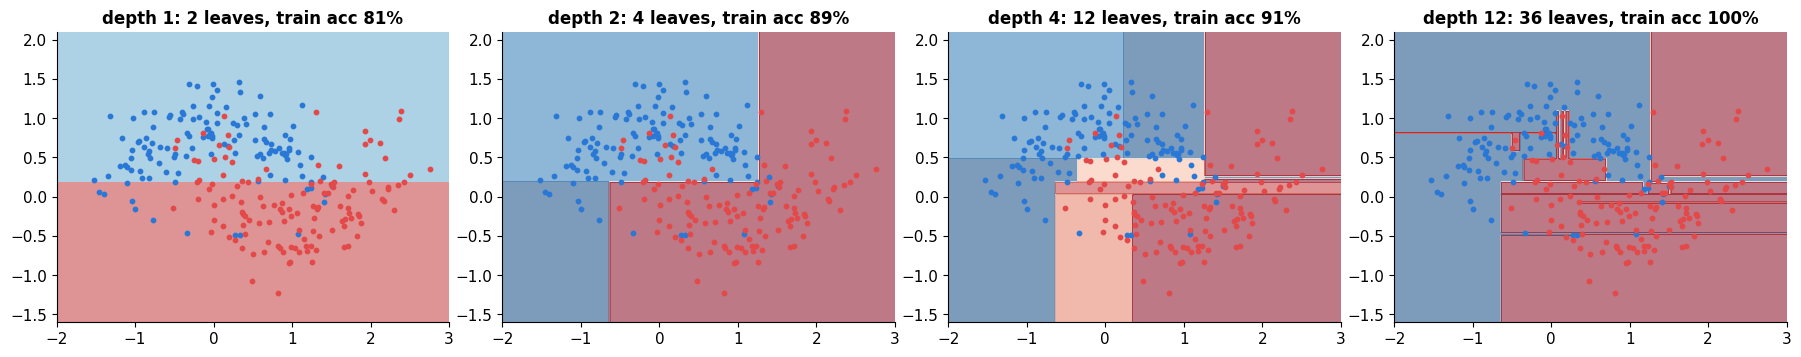

In [4]:
Xm, ym = make_moons(250, noise=0.3, random_state=1)
g1, g2 = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.6, 2.1, 300)); G = np.column_stack([g1.ravel(), g2.ravel()])
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, depth in zip(axes, [1, 2, 4, 12]):
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xm, ym)
    P = t.predict_proba(G)[:, 1].reshape(g1.shape)
    ax.contourf(g1, g2, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.55)
    ax.scatter(*Xm[ym == 0].T, s=10, color=C["blue"]); ax.scatter(*Xm[ym == 1].T, s=10, color=C["red"])
    ax.set(title=f"depth {depth}: {t.get_n_leaves()} leaves, train acc {t.score(Xm, ym):.0%}", aspect="equal"); ax.grid(False)
fig.tight_layout(); plt.show()

Every region is a rectangle. Depth 1 is a single cut (a "decision stump", the building block of boosting in notebook 13); depth 12 has carved out tiny boxes around individual noisy points.

---
## 4. Classification trees: Gini, entropy, and why not just count errors

For classification, a leaf predicts its **majority class**, and its class probabilities are the fractions $\hat p_k$ of each class in the leaf. To score a split we need an **impurity** measure $Q$: zero for a pure leaf (one class only), largest for an even mix. ISYE 4600 (W13) lists three:

| Impurity | Formula | Two classes, $p = $ fraction of class 1 |
|---|---|---|
| Misclassification error | $1 - \max_k \hat p_k$ | $\min(p, 1-p)$ |
| **Gini index** | $\sum_k \hat p_k(1 - \hat p_k)$ | $2p(1-p)$ |
| **Entropy** (cross-entropy) | $-\sum_k \hat p_k\log_2\hat p_k$ | $-p\log_2 p - (1-p)\log_2(1-p)$ |

A split is scored by the **size-weighted** impurity of its children, $\frac{N_L}{N}Q_L + \frac{N_R}{N}Q_R$, and we pick the split that lowers it most (for entropy, that reduction is called **information gain**).

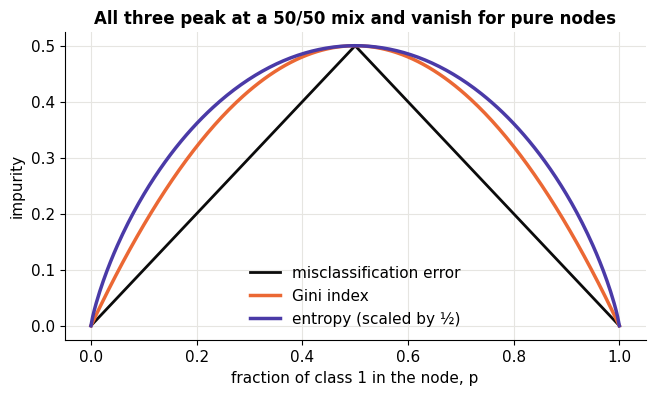

In [5]:
p = np.linspace(0, 1, 300)
H = -(np.where(p > 0, p * np.log2(np.maximum(p, 1e-12)), 0) + np.where(p < 1, (1 - p) * np.log2(np.maximum(1 - p, 1e-12)), 0))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(p, np.minimum(p, 1 - p), color=C["ink"], lw=2, label="misclassification error")
ax.plot(p, 2 * p * (1 - p), color=C["orange"], lw=2.5, label="Gini index")
ax.plot(p, H / 2, color=C["violet"], lw=2.5, label="entropy (scaled by ½)")
ax.set(xlabel="fraction of class 1 in the node, p", ylabel="impurity", title="All three peak at a 50/50 mix and vanish for pure nodes"); ax.legend()
plt.show()

Why does CART prefer Gini or entropy over the error rate itself? ISYE notes that they're "more sensitive to changes in $\hat p$." Here's a concrete case. A node with 400 points of each class; two candidate splits:

In [6]:
def impurities(counts):
    n = sum(counts); p_ = np.array(counts) / n
    return dict(error=1 - p_.max(), gini=1 - np.sum(p_ ** 2), entropy=-np.sum([q * np.log2(q) for q in p_ if q > 0]))

def split_score(children):
    N = sum(sum(c) for c in children)
    return {k: sum(sum(c) / N * impurities(c)[k] for c in children) for k in ["error", "gini", "entropy"]}

parent = impurities([400, 400])
A = split_score([[300, 100], [100, 300]]); B = split_score([[200, 400], [200, 0]])
print(f"{'':28s} {'error':>8} {'Gini':>8} {'entropy':>8}")
print(f"{'parent (400/400)':28s} {parent['error']:8.3f} {parent['gini']:8.3f} {parent['entropy']:8.3f}")
print(f"{'split A: (300,100)|(100,300)':28s} {A['error']:8.3f} {A['gini']:8.3f} {A['entropy']:8.3f}")
print(f"{'split B: (200,400)|(200,0)':28s} {B['error']:8.3f} {B['gini']:8.3f} {B['entropy']:8.3f}")

                                error     Gini  entropy
parent (400/400)                0.500    0.500    1.000
split A: (300,100)|(100,300)    0.250    0.375    0.811
split B: (200,400)|(200,0)      0.250    0.333    0.689


Misclassification error rates the two splits as **equally good** (both make 200 mistakes). But split B creates a perfectly **pure** node (200, 0), which needs no further splitting, while A leaves two muddled nodes. Gini and entropy both prefer B. Because they're strictly concave, they reward making *any* child purer, even when the majority vote (and so the error count) doesn't change. That makes the greedy search more productive. In practice Gini and entropy almost always choose the same splits; Gini is slightly cheaper (no logarithm), so it's scikit-learn's default.

---
## 5. A CART implementation from scratch

The whole algorithm fits in a page. The one trick is making the split search fast: for each feature, **sort** the node's points once, then use **cumulative sums** to get the impurity of every cut point in a single vectorized pass.

In [7]:
class Node:
    def __init__(self, value, n): self.value, self.n, self.feature, self.thr, self.left, self.right = value, n, None, None, None, None

class CART:
    """Classification (Gini) or regression (squared error) tree. max_features < d gives the random-forest variant."""
    def __init__(self, task="classification", max_depth=None, min_samples_leaf=1, max_features=None, rng=None):
        self.task, self.max_depth, self.min_leaf, self.max_features = task, max_depth or 10**9, min_samples_leaf, max_features
        self.rng = rng or np.random.default_rng(0)

    def _leaf_value(self, y):
        return np.bincount(y, minlength=self.K) / len(y) if self.task == "classification" else y.mean()

    def _best_split(self, X, y):
        m, d = X.shape; best = (np.inf, None, None)
        feats = self.rng.choice(d, self.max_features, replace=False) if self.max_features else range(d)
        for j in feats:
            order = np.argsort(X[:, j]); xs, ys = X[order, j], y[order]
            valid = np.where(xs[:-1] < xs[1:])[0]                                  # can only cut between distinct values
            valid = valid[(valid + 1 >= self.min_leaf) & (m - valid - 1 >= self.min_leaf)]
            if len(valid) == 0: continue
            nL = valid + 1.0; nR = m - nL
            if self.task == "classification":
                Y = np.eye(self.K)[ys]; cL = np.cumsum(Y, 0)[valid]; cR = Y.sum(0) - cL
                score = nL * (1 - ((cL / nL[:, None]) ** 2).sum(1)) + nR * (1 - ((cR / nR[:, None]) ** 2).sum(1))   # N·Gini, summed
            else:
                s1 = np.cumsum(ys)[valid]; s2 = np.cumsum(ys ** 2)[valid]; S1, S2 = ys.sum(), (ys ** 2).sum()
                score = (s2 - s1 ** 2 / nL) + ((S2 - s2) - (S1 - s1) ** 2 / nR)                                    # SSE left + right
            i = np.argmin(score)
            if score[i] < best[0]: best = (score[i], j, (xs[valid[i]] + xs[valid[i] + 1]) / 2)
        return best

    def _grow(self, X, y, depth):
        node = Node(self._leaf_value(y), len(y))
        pure = (len(np.unique(y)) == 1) if self.task == "classification" else np.allclose(y, y[0])
        if depth >= self.max_depth or len(y) < 2 * self.min_leaf or pure:
            return node
        score, j, thr = self._best_split(X, y)
        if j is None: return node
        mask = X[:, j] <= thr
        node.feature, node.thr = j, thr
        node.left, node.right = self._grow(X[mask], y[mask], depth + 1), self._grow(X[~mask], y[~mask], depth + 1)
        return node

    def fit(self, X, y):
        if self.task == "classification": self.K = int(y.max()) + 1
        self.root = self._grow(X, y, 0); return self

    def _predict_one(self, x):
        node = self.root
        while node.feature is not None:
            node = node.left if x[node.feature] <= node.thr else node.right
        return node.value

    def predict_value(self, X): return np.array([self._predict_one(x) for x in X])
    def predict(self, X):
        v = self.predict_value(X); return v.argmax(1) if self.task == "classification" else v

    def show(self, names=None, node=None, indent="", label=""):
        node = node or self.root; names = names or [f"x{j}" for j in range(100)]
        if node.feature is None:
            val = f"P = {np.round(node.value, 2)}" if self.task == "classification" else f"predict {node.value:.2f}"
            print(f"{indent}{label}→ {val}  (n = {node.n})"); return
        print(f"{indent}{label}{names[node.feature]} ≤ {node.thr:.3g}?  (n = {node.n})")
        child_indent = indent + " " * (len(label) + 2)
        self.show(names, node.left, child_indent, "yes: "); self.show(names, node.right, child_indent, "no:  ")

ours = CART(max_depth=3).fit(Xm, ym)
ours.show(names=["x₁", "x₂"])
sk = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xm, ym)
print(f"\nagreement with scikit-learn's tree on 2,000 random points: {np.mean(ours.predict(G[::45]) == sk.predict(G[::45])):.1%}")

x₂ ≤ 0.188?  (n = 250)
  yes: x₁ ≤ -0.641?  (n = 110)
         yes: → P = [1. 0.]  (n = 6)
         no:  x₂ ≤ 0.0305?  (n = 104)
                yes: → P = [0.06 0.94]  (n = 80)
                no:  → P = [0.21 0.79]  (n = 24)
  no:  x₁ ≤ 1.27?  (n = 140)
         yes: x₂ ≤ 0.485?  (n = 125)
                yes: → P = [0.67 0.33]  (n = 27)
                no:  → P = [0.92 0.08]  (n = 98)
         no:  x₂ ≤ 0.267?  (n = 15)
                yes: → P = [0.5 0.5]  (n = 2)
                no:  → P = [0. 1.]  (n = 13)

agreement with scikit-learn's tree on 2,000 random points: 100.0%


(Any disagreement comes from ties: when two splits score identically, the implementations may break the tie differently.) The printed rules *are* the model, which is why trees are popular wherever decisions must be explained: credit, medicine, policy.

---
## 6. Overfitting, depth, and cost-complexity pruning

Left alone, a tree keeps splitting until every leaf is pure: 100% training accuracy and wild overfitting (section 3's depth-12 picture). Two ways to control it:

- **Stop early** ("pre-pruning"): limit the depth, require a minimum number of points per leaf, or require a minimum impurity decrease. Simple, but short-sighted: a split that looks useless may enable great splits below it.
- **Grow big, then prune** ("post-pruning", ISYE W13): grow a large tree, then collapse subtrees that don't earn their keep. CART uses **cost-complexity pruning**, which trades fit against the number of leaves $|T|$:

$$C_\alpha(T) = \sum_{\text{leaves } j} N_j\,Q_j(T) \;+\; \alpha\,|T|$$

(Total impurity, or SSE for regression, plus a price $\alpha$ per leaf. It's the same "loss + penalty × complexity" template as ridge and the Lasso.) For each $\alpha$ there's a best subtree, and as $\alpha$ grows the optimal tree shrinks through a nested sequence of subtrees, the **pruning path**. Choose $\alpha$ by cross-validation:

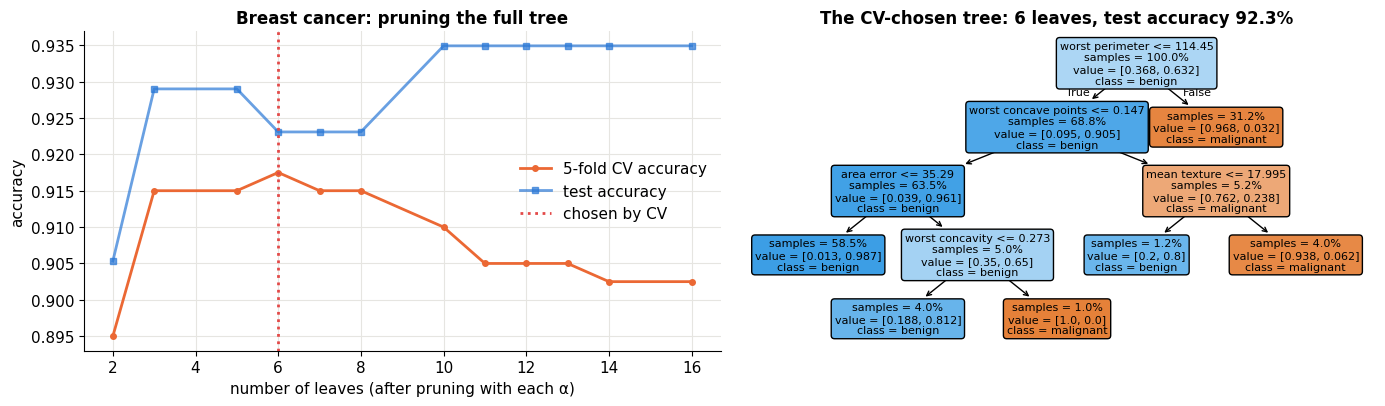

In [8]:
bc = load_breast_cancer(); Xb, yb = bc.data, bc.target
perm = np.random.default_rng(0).permutation(len(yb)); trb, teb = perm[:400], perm[400:]
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(Xb[trb], yb[trb])
alphas = path.ccp_alphas[:-1]
folds = np.array_split(np.random.default_rng(1).permutation(len(trb)), 5)
cv_acc, n_leaves, test_acc = [], [], []
for a in alphas:
    accs = []
    for va in folds:
        tr_ = np.setdiff1d(np.arange(len(trb)), va)
        accs.append(DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(Xb[trb][tr_], yb[trb][tr_]).score(Xb[trb][va], yb[trb][va]))
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(Xb[trb], yb[trb])
    cv_acc.append(np.mean(accs)); n_leaves.append(t.get_n_leaves()); test_acc.append(t.score(Xb[teb], yb[teb]))
best_a = alphas[int(np.argmax(cv_acc))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
ax1.plot(n_leaves, cv_acc, "-o", color=C["orange"], ms=4, label="5-fold CV accuracy")
ax1.plot(n_leaves, test_acc, "-s", color=C["blue"], ms=4, alpha=0.7, label="test accuracy")
ax1.axvline(n_leaves[int(np.argmax(cv_acc))], color=C["red"], ls=":", label="chosen by CV")
ax1.set(xlabel="number of leaves (after pruning with each α)", ylabel="accuracy", title="Breast cancer: pruning the full tree"); ax1.legend()
pruned = DecisionTreeClassifier(ccp_alpha=best_a, random_state=0).fit(Xb[trb], yb[trb])
plot_tree(pruned, feature_names=bc.feature_names, class_names=["malignant", "benign"], filled=True, rounded=True, fontsize=8, ax=ax2, impurity=False, proportion=True)
ax2.set_title(f"The CV-chosen tree: {pruned.get_n_leaves()} leaves, test accuracy {pruned.score(Xb[teb], yb[teb]):.1%}")
fig.tight_layout(); plt.show()

Cross-validation peaks at 6 leaves and declines for bigger trees. On this particular test split, the full 16-leaf tree happens to score about one point higher (93.5% vs. 92.3%, a difference of 2 patients out of 169, well within noise). Either way, pruning to 6 leaves costs almost nothing in accuracy and buys a tree that fits on a slide, one a doctor could check by hand. That's the typical result: a large tree's extra leaves add little real predictive power.

---
## 7. Why a single tree is unstable

Here's the catch ISYE W13 emphasizes: trees have **high variance**. Because the splits are chosen greedily, a small change near the top of the tree changes everything below it. Fit the same depth-4 tree to five bootstrap resamples of the same data:

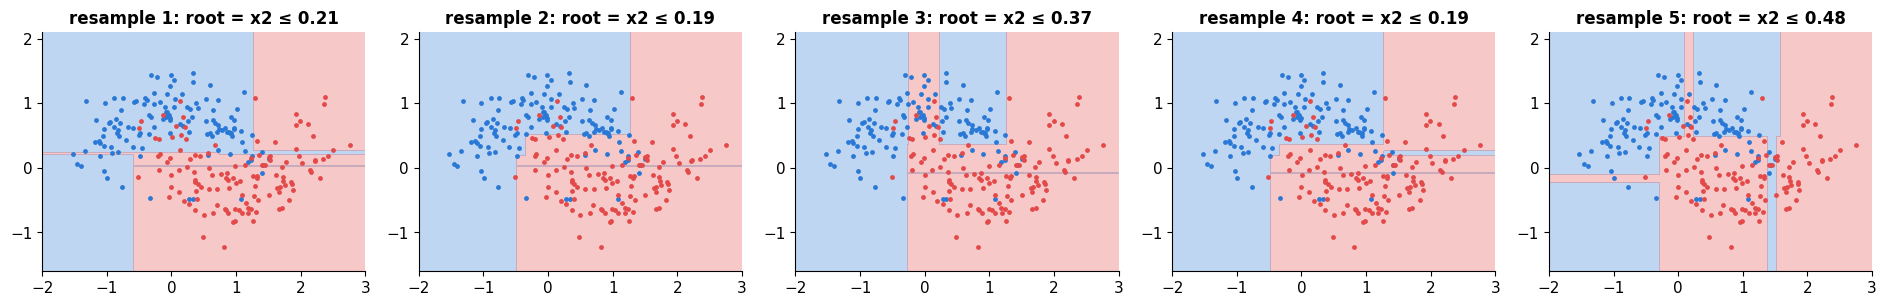

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for s, ax in enumerate(axes):
    idx = np.random.default_rng(s).integers(0, len(ym), len(ym))
    t = DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xm[idx], ym[idx])
    ax.contourf(g1, g2, t.predict(G).reshape(g1.shape), levels=[-0.5, 0.5, 1.5], colors=[C["blue"], C["red"]], alpha=0.3)
    ax.scatter(*Xm[ym == 0].T, s=6, color=C["blue"]); ax.scatter(*Xm[ym == 1].T, s=6, color=C["red"])
    root = t.tree_; ax.set(aspect="equal", title=f"resample {s + 1}: root = x{root.feature[0] + 1} ≤ {root.threshold[0]:.2f}"); ax.grid(False)
fig.tight_layout(); plt.show()

Same data-generating process, five noticeably different trees, sometimes even with a different first question. Low bias (a deep tree can fit almost anything), high variance (what it fits depends heavily on the particular sample). Notebook 06 tells us what to do with a low-bias, high-variance estimator: **average many of them**. For that we need many datasets, and the bootstrap gives them to us for free.

---
## 8. The bootstrap

We have one dataset. The **bootstrap** (Efron, 1979) pretends the dataset *is* the population and draws new datasets from it: **$N$ draws with replacement from the $N$ training points** (ISYE W13). Each resample has some points repeated and others left out. Recomputing an estimate on many resamples shows how much it would vary across datasets, without collecting any new data.

A quick example: how uncertain is the **median** rent of 40 apartments? There's no simple formula for the median's standard error, but the bootstrap doesn't need one:

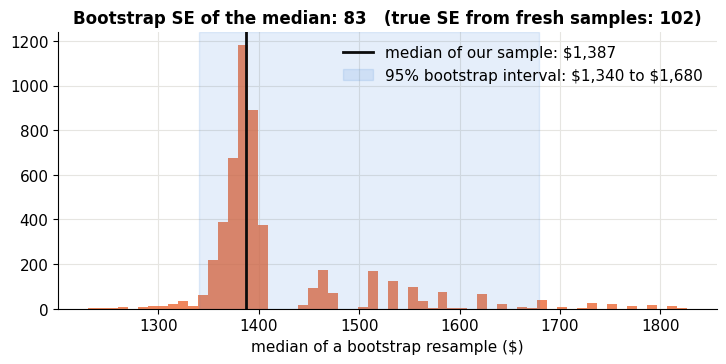

Fraction of distinct points in a bootstrap resample: 0.631   (theory: 1 − (1 − 1/N)^N → 1 − 1/e ≈ 0.632)


In [10]:
r_ = np.random.default_rng(3)
rents = np.round(r_.lognormal(np.log(1500), 0.35, 40))
boot_medians = np.array([np.median(r_.choice(rents, len(rents), replace=True)) for _ in range(5000)])
true_spread = np.std([np.median(np.round(np.random.default_rng(100 + i).lognormal(np.log(1500), 0.35, 40))) for i in range(5000)])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.hist(boot_medians, bins=60, color=C["orange"], alpha=0.8)
ax.axvline(np.median(rents), color=C["ink"], lw=2, label=f"median of our sample: \\${np.median(rents):,.0f}")
lo, hi = np.percentile(boot_medians, [2.5, 97.5])
ax.axvspan(lo, hi, color=C["blue"], alpha=0.12, label=f"95% bootstrap interval: \\${lo:,.0f} to \\${hi:,.0f}")
ax.set(xlabel="median of a bootstrap resample ($)", title=f"Bootstrap SE of the median: {boot_medians.std():.0f}   (true SE from fresh samples: {true_spread:.0f})"); ax.legend()
plt.show()

frac_in = np.mean([len(np.unique(np.random.default_rng(i).integers(0, 1000, 1000))) / 1000 for i in range(200)])
print(f"Fraction of distinct points in a bootstrap resample: {frac_in:.3f}   (theory: 1 − (1 − 1/N)^N → 1 − 1/e ≈ 0.632)")

The bootstrap standard error is in the right ballpark of the true one (which we could compute here only because we know how the data was simulated), though about 20% low. The median is actually one of the bootstrap's harder cases: with only 40 points, a resample's median can only land on a few distinct values, hence the lumpy histogram. For smooth statistics like means and regression coefficients it does better. And note the last line: each bootstrap sample contains only about **63%** of the distinct original points; the other ~37% are left out. That fact powers section 10.

---
## 9. Bagging and random forests

**Bagging** (bootstrap aggregating; Breiman, 1996): draw $B$ bootstrap samples, grow a deep tree on each, and **average** their predictions (regression) or take a **majority vote** (classification). Each tree has low bias and high variance; averaging keeps the low bias and shrinks the variance.

How much does averaging help? If each tree's prediction has variance $\sigma^2$ and any two trees are correlated with correlation $\rho$, the average of $B$ trees has variance

$$\text{Var}\Big(\frac1B\sum_{b=1}^B T_b\Big) = \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2$$

The second term vanishes as $B$ grows, but the first doesn't: **correlation between the trees sets a floor**. Bagged trees are quite correlated (they're all grown on similar data, and they all tend to pick the same strong feature for the first split).

**Random forests** (Breiman, 2001) attack $\rho$ directly: at **every split**, the tree may only choose among a **random subset** of $m_{\text{try}}$ features (typically $\sqrt{d}$ for classification, $d/3$ for regression). That forces different trees to use different features, which decorrelates them. Each individual tree gets a bit worse, but the average gets better.

The formula, visualized:

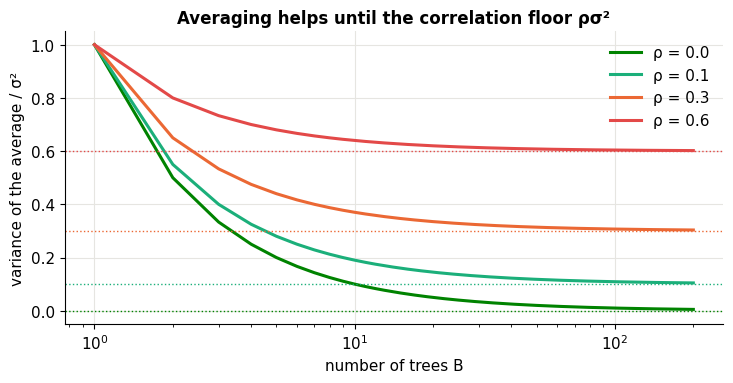

In [11]:
B = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for rho, col in zip([0.0, 0.1, 0.3, 0.6], [C["green"], C["aqua"], C["orange"], C["red"]]):
    ax.plot(B, rho + (1 - rho) / B, color=col, lw=2.2, label=f"ρ = {rho}")
    ax.axhline(rho, color=col, ls=":", lw=1)
ax.set(xscale="log", xlabel="number of trees B", ylabel="variance of the average / σ²", title="Averaging helps until the correlation floor ρσ²"); ax.legend()
plt.show()

Now build a random forest from scratch with our `CART` class: the only changes from a single tree are the bootstrap sample and `max_features`. Watch the vote form as trees are added:

In [12]:
class RandomForest:
    def __init__(self, n_trees=100, max_features="sqrt", max_depth=None, min_samples_leaf=1, seed=0):
        self.n_trees, self.max_features, self.max_depth, self.min_leaf, self.seed = n_trees, max_features, max_depth, min_samples_leaf, seed
    def fit(self, X, y):
        rng = np.random.default_rng(self.seed); m, d = X.shape
        mf = max(1, int(np.sqrt(d))) if self.max_features == "sqrt" else self.max_features
        self.trees, self.inbag = [], []
        for b in range(self.n_trees):
            idx = rng.integers(0, m, m)                                            # bootstrap sample
            self.trees.append(CART(max_depth=self.max_depth, min_samples_leaf=self.min_leaf, max_features=mf, rng=rng).fit(X[idx], y[idx]))
            self.inbag.append(np.bincount(idx, minlength=m) > 0)
        return self
    def predict_proba(self, X, n=None):
        return np.mean([t.predict_value(X) for t in self.trees[:n]], axis=0)

rf_ours = RandomForest(n_trees=60, max_features=1, seed=0).fit(Xm, ym)       # with only 2 features, try 1 random feature per split
h1, h2 = np.meshgrid(np.linspace(-2, 3, 110), np.linspace(-1.6, 2.1, 90))
Gx = np.column_stack([h1.ravel(), h2.ravel()])
tree_probs = np.array([t.predict_value(Gx)[:, 1] for t in rf_ours.trees])          # each tree's P(red) on the grid
fig, ax = plt.subplots(figsize=(7, 5), dpi=72)
def frame(k):
    ax.clear()
    P = tree_probs[:k].mean(0).reshape(h1.shape)
    ax.contourf(h1, h2, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
    ax.contour(h1, h2, P, levels=[0.5], colors=C["ink"], linewidths=1.8)
    ax.scatter(*Xm[ym == 0].T, s=8, color=C["blue"]); ax.scatter(*Xm[ym == 1].T, s=8, color=C["red"])
    ax.set(xlim=(-2, 3), ylim=(-1.6, 2.1), aspect="equal", title=f"random forest: average of {k} tree{'s' if k > 1 else ''}"); ax.grid(False)
    return []
show_anim(animation.FuncAnimation(fig, frame, frames=[1, 2, 3, 5, 8, 12, 20, 30, 45, 60], interval=500))

One tree gives a blocky, overconfident map. As trees are added, the boundary smooths out and the probabilities become graded, even though every individual tree is still made of rectangles.

Now the comparison on the breast-cancer data, as in ISYE 4600 HW4 (single CART vs. random forest, test error vs. number of trees):

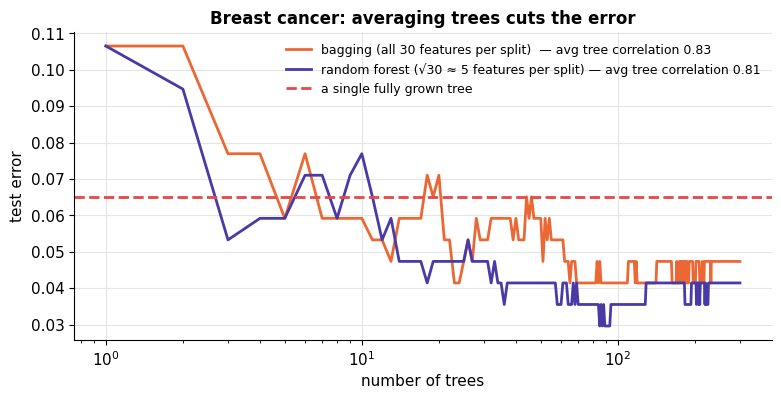

In [13]:
B_max = 300
rf = RandomForestClassifier(n_estimators=B_max, max_features="sqrt", random_state=0, n_jobs=-1).fit(Xb[trb], yb[trb])
bag = RandomForestClassifier(n_estimators=B_max, max_features=None, random_state=0, n_jobs=-1).fit(Xb[trb], yb[trb])     # max_features=None = plain bagging
single = DecisionTreeClassifier(random_state=0).fit(Xb[trb], yb[trb])

def staged_error(forest, X, y):
    probs = np.cumsum([t.predict_proba(X)[:, 1] for t in forest.estimators_], axis=0) / np.arange(1, len(forest.estimators_) + 1)[:, None]
    return np.mean((probs > 0.5) != y[None, :], axis=1)

def tree_correlation(forest, X):
    P = np.array([t.predict_proba(X)[:, 1] for t in forest.estimators_[:100]])
    Cm = np.corrcoef(P); return Cm[np.triu_indices(len(P), 1)].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, B_max + 1), staged_error(bag, Xb[teb], yb[teb]), color=C["orange"], lw=2, label=f"bagging (all 30 features per split)  — avg tree correlation {tree_correlation(bag, Xb[teb]):.2f}")
ax.plot(np.arange(1, B_max + 1), staged_error(rf, Xb[teb], yb[teb]), color=C["violet"], lw=2, label=f"random forest (√30 ≈ 5 features per split) — avg tree correlation {tree_correlation(rf, Xb[teb]):.2f}")
ax.axhline(1 - single.score(Xb[teb], yb[teb]), color=C["red"], ls="--", label="a single fully grown tree")
ax.set(xscale="log", xlabel="number of trees", ylabel="test error", title="Breast cancer: averaging trees cuts the error"); ax.legend(fontsize=9)
plt.show()

Both ensembles beat the single tree after a few dozen trees. The random forest ends up a little lower than plain bagging, with slightly less correlated trees, but on this dataset the gap is modest: one feature (tumor size) is so dominant that even with 5 random candidates per split, most trees still find a size-related feature near the top. The decorrelation trick pays off most when several features are strong, so that bagged trees would all lean on the same one. Notice also that **adding trees doesn't cause overfitting**: after the early drop the curve just wobbles around a plateau (the wobbles are test-set noise from 169 patients). Unlike depth or $\lambda$, the number of trees isn't a complexity knob; more trees only cost more compute.

> 🤔 **Question: Do random forests need tuning?**
>
> Surprisingly little, which is a big part of their appeal. Defaults (a few hundred fully grown trees, $m_{\text{try}} = \sqrt d$) are often close to the best. The parameters that matter most are $m_{\text{try}}$ (smaller = more decorrelation, more bias per tree) and the minimum leaf size (larger = smoother). They also need no feature scaling and handle mixed numeric and categorical features. That's why "try a random forest" is a standard first move on any tabular problem.

---
## 10. Out-of-bag error: free cross-validation

Each tree was trained on a bootstrap sample containing ~63% of the points, so each training point was **left out** of about 37% of the trees. For each point, average the predictions of **only the trees that never saw it**. Those predictions are honest, like cross-validation, and they come for free with the forest (ISYE W13: "OOB error as an efficient alternative to cross-validation").

In [14]:
rf_oob = RandomForest(n_trees=150, max_features=5, seed=1).fit(Xb[trb], yb[trb])
votes = np.zeros((len(trb), 2)); counts = np.zeros(len(trb))
for t, inb in zip(rf_oob.trees, rf_oob.inbag):
    oob = ~inb
    votes[oob] += t.predict_value(Xb[trb][oob]); counts[oob] += 1
oob_err = np.mean(votes.argmax(1)[counts > 0] != yb[trb][counts > 0])
test_err = np.mean(rf_oob.predict_proba(Xb[teb]).argmax(1) != yb[teb])
print(f"each training point was out-of-bag for {counts.mean():.0f} of 150 trees on average ({counts.mean()/150:.0%}, theory ≈ 37%)")
print(f"OOB error (from the training data alone): {oob_err:.3f}")
print(f"test error (on held-out data):            {test_err:.3f}")
print(f"scikit-learn's OOB estimate:              {1 - RandomForestClassifier(150, oob_score=True, random_state=1).fit(Xb[trb], yb[trb]).oob_score_:.3f}")

each training point was out-of-bag for 55 of 150 trees on average (37%, theory ≈ 37%)
OOB error (from the training data alone): 0.043
test error (on held-out data):            0.041


scikit-learn's OOB estimate:              0.037


The OOB error lands close to the true test error without setting aside any data or refitting anything. In practice people use it to tune $m_{\text{try}}$ or the leaf size cheaply.

---
## 11. Feature importance: impurity-based vs. permutation, and a trap

Forests aren't as readable as a single tree, but they can tell you which features mattered (ISYE W13 lists both kinds):

- **Impurity-based importance** (mean decrease in impurity): add up how much each feature's splits reduced the Gini impurity, across all trees. Free to compute, but **biased**: features with many possible cut points (continuous features, IDs, high-cardinality categories) get more chances to produce a good-looking split by luck.
- **Permutation importance:** shuffle one feature's values on held-out data (breaking its relationship with the label) and measure how much accuracy drops. Slower, but measures what actually matters for prediction.

To show the trap, use a dataset where we know the truth: two informative continuous features, two informative **binary** features, and two pure-noise features, one continuous (hundreds of possible cut points) and one a coin flip (a single cut point):

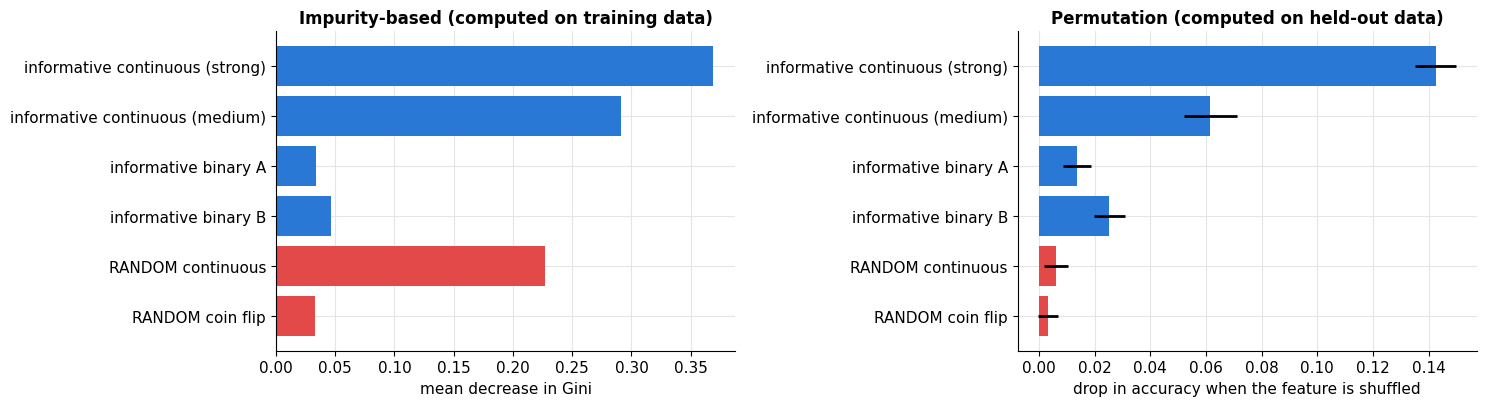

In [15]:
r_ = np.random.default_rng(0); n_ = 2400
x1_, x2_, b1_, b2_ = r_.normal(size=n_), r_.normal(size=n_), r_.integers(0, 2, n_), r_.integers(0, 2, n_)
logit = 1.2 * x1_ + 0.8 * x2_ + 1.0 * b1_ + 0.8 * b2_ - 0.9
y_imp = (r_.random(n_) < 1 / (1 + np.exp(-logit))).astype(int)
X_imp = np.column_stack([x1_, x2_, b1_, b2_, r_.normal(size=n_), r_.integers(0, 2, n_)])
names_i = ["informative continuous (strong)", "informative continuous (medium)", "informative binary A", "informative binary B",
           "RANDOM continuous", "RANDOM coin flip"]
tri, tei = np.arange(400), np.arange(400, n_)
rf_i = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X_imp[tri], y_imp[tri])
pimp = permutation_importance(rf_i, X_imp[tei], y_imp[tei], n_repeats=20, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
cols = [C["red"] if "RANDOM" in n else C["blue"] for n in names_i]
axes[0].barh(names_i[::-1], rf_i.feature_importances_[::-1], color=cols[::-1]); axes[0].set(title="Impurity-based (computed on training data)", xlabel="mean decrease in Gini")
axes[1].barh(names_i[::-1], pimp.importances_mean[::-1], xerr=pimp.importances_std[::-1], color=cols[::-1])
axes[1].set(title="Permutation (computed on held-out data)", xlabel="drop in accuracy when the feature is shuffled")
fig.tight_layout(); plt.show()

The impurity-based ranking puts the **random continuous** feature in third place, far ahead of both genuinely informative binary features. With hundreds of cut points to choose from, deep trees always find *some* split on it that separates a few training points by chance, and those lucky splits pile up across 300 trees. The coin flip has only one possible split, so it can't exploit luck the same way. Under permutation importance on held-out data, the random continuous feature drops to roughly zero, below every real feature, where it belongs.

Two more cautions for both methods: **correlated features share credit** (in the breast-cancer data, radius, perimeter and area measure nearly the same thing, so shuffling any one of them barely hurts: the others cover for it), and importance describes the *model*, not causation in the world.

---
## 12. Summary

| | Single tree | Bagging | Random forest |
|---|---|---|---|
| Fit | greedy splits minimizing SSE / Gini / entropy | $B$ deep trees on bootstrap samples | bagging + random $m_{\text{try}}$ features per split |
| Bias | low (deep) to high (shallow) | low | low (slightly higher per tree) |
| Variance | **high** | lower | lowest (decorrelated trees) |
| Interpretable | yes: if-then rules | no | no (use importances) |
| Complexity control | depth, leaf size, **cost-complexity pruning** | — (more trees never hurts) | $m_{\text{try}}$, leaf size |
| Free validation | — | OOB | OOB |

**Strengths of trees:** no scaling, mixed feature types, automatic interactions and nonlinearity, interpretability (single trees), robustness to outliers in $x$. **Weaknesses:** axis-aligned boxes (a diagonal boundary needs many steps), piecewise-constant predictions (no extrapolation beyond the training range), instability (single trees). Random forests fix the instability; **boosting** (notebook 13) takes the opposite route, combining *shallow* trees sequentially to reduce *bias*.

### ✏️ Exercises

1. Finish the by-hand tree from section 2: find the best split inside each half. Then compute the cost-complexity $C_\alpha$ for the depth-1 and depth-2 trees with $\alpha = 5$. Which wins?
2. Show that a regression tree cannot predict values outside the range of the training targets. Demonstrate it by fitting a forest to $y = 2x$ on $[0, 5]$ and predicting at $x = 8$. Compare with linear regression.
3. Build the XOR dataset (labels = sign of $x_1x_2$) and fit a depth-2 tree. Why does the greedy first split look useless, yet the depth-2 tree is perfect?
4. Vary $m_{\text{try}}$ from 1 to 30 on the breast-cancer data and plot OOB error and the average between-tree correlation. Is there a sweet spot?
5. Implement **permutation importance** yourself for the random forest and check it against scikit-learn's. Then run it on the breast-cancer data: why is almost every feature's importance near zero there?
6. Fit a random forest **regressor** to notebook 05's diabetes data and compare its test $R^2$ with linear regression. Is the extra flexibility worth it here?

### References

- ISYE 4600 W13 (Decision Trees & Random Forests: CART, regression and classification trees, split search, impurity measures, pruning, bootstrap, bagging, random forests, OOB, feature importance) and HW4 Q5 (CART vs. random forest).
- L. Breiman, J. Friedman, R. Olshen & C. Stone, *Classification and Regression Trees* (1984).
- L. Breiman, *Bagging Predictors*, Machine Learning (1996); *Random Forests*, Machine Learning (2001).
- B. Efron, *Bootstrap Methods: Another Look at the Jackknife*, Annals of Statistics (1979).
- T. Hastie, R. Tibshirani & J. Friedman, *The Elements of Statistical Learning*, Sections 9.2 and 15.
- C. Strobl et al., *Bias in random forest variable importance measures*, BMC Bioinformatics (2007).

**Next → [13 · Boosting](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/13_boosting.ipynb)**